# 8.0 — Experimentos comparativos: aproximación publicada vs codificación directa

Comparación controlada, sobre **la misma instancia y con el mismo presupuesto
de evaluaciones**, de los enfoques de los dos papers publicados y de la nueva
aproximación con codificación directa desarrollada en los cuadernos 6.0 y 7.0:

| # | Método | Codificación | Objetivo | Máscara (qué trenes circulan) | Referencia |
|---|---|---|---|---|---|
| M0 | Greedy | horarios solicitados | — | heurística (soltar el más barato) | Paper 1, Alg. 2 |
| M1 | GA-mealpy | salidas reales | revenue | heurística CaSP (estática) | Paper 1 |
| M2 | GA-mealpy ×F | salidas reales | `revenue × Jain(25)` | heurística CaSP (estática) | Paper 2 |
| M3 | GSA reparado | salidas reales | revenue | heurística CaSP (estática) | Paper 1 (línea GSA) |
| M4 | GA directo | máscara `b` + deltas `δ` | revenue penalizado | **evoluciona con el genoma** | Cuaderno 6.0 |
| M5 | NSGA-II bi-obj | máscara `b` + deltas `δ` | `[revenue, Jain(25)]` | **evoluciona con el genoma** | Cuaderno 7.0 |

Diseño:

- **Instancia común**: la del cuaderno 0.0 (`data/synthetic/`), 50 servicios
  Madrid→Barcelona, 3 RUs, 103 pares en conflicto sobre los horarios
  solicitados.
- **Presupuesto igual para todas las metaheurísticas**: `pop_size = 40`,
  `epoch = 100` (4000 evaluaciones por ejecución), 5 semillas
  `[7, 21, 42, 63, 84]`.
- **Evaluador común**: toda solución final (de cualquier método) se mide con
  el verificador dinámico del backend GA (conflictos recomputados sobre los
  horarios *decodificados*, validado 1:1 contra `robin`), de modo que la
  comparación no depende del objetivo interno de cada método.


## 1. Configuración e instancia común

Cargamos la instancia dos veces: como problema de codificación directa
(`GATimetabling`, para M4/M5 y como evaluador común) y como formulación de
variables reales con máscara heurística (`MealpyTimetabling`, para M1/M2/M3).
Ambas comparten el mismo `revenue.yaml`, por lo que el revenue de un servicio
es idéntico en las dos formulaciones.


In [1]:
import itertools
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

from craft.common import Boundaries, Solution
from craft.fairness import FairnessMetrics
from craft.ga import GA, NSGA2, load_problem, revenue_fairness_objectives
from craft.ga.objectives import compute_capacities
from craft.gsa import GSA
from craft.mealpy import MealpyTimetabling

SEEDS = [7, 21, 42, 63, 84]
POP_SIZE = 40
EPOCH = 100
CONFLICT_PENALTY = 2.0
ALPHA = {"jain": 25.0, "gini": 10.0, "atkinson": 25.0}
RESULTS_DIR = Path("../data/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TIMETABLE = Path("../data/synthetic/timetable.yaml")
REVENUE = Path("../data/synthetic/revenue.yaml")


In [2]:
ga_problem = load_problem(TIMETABLE, REVENUE, conflict_penalty=CONFLICT_PENALTY)

import yaml

revenue_behavior = yaml.safe_load(REVENUE.read_text())["services"]
tt_mono = MealpyTimetabling(
    requested_services=ga_problem.services,
    revenue_behavior=revenue_behavior,
    safe_headway=ga_problem.safe_headway,
    max_stop_time=ga_problem.max_stop_time,
)
tt_fair = MealpyTimetabling(
    requested_services=ga_problem.services,
    revenue_behavior=revenue_behavior,
    safe_headway=ga_problem.safe_headway,
    max_stop_time=ga_problem.max_stop_time,
    fair_index="Jain",
    alpha=ALPHA["jain"],
)

assert len(tt_mono.boundaries.real) == len(ga_problem.reference_departures)
assert tt_mono.revenue == ga_problem.revenue_behavior

print(f"Servicios: {ga_problem.n_services} | variables reales: {len(ga_problem.reference_departures)} | genes: {ga_problem.genome_size}")

requested_genome = np.zeros(ga_problem.genome_size, dtype=np.int64)
for block in ga_problem.slices:
    requested_genome[block.start] = 1
print(f"Pares en conflicto (solicitados): {len(ga_problem.conflicting_pairs(requested_genome))}")
print(f"Capacidades por RU (% de servicios solicitados): {compute_capacities(ga_problem.revenue_behavior)}")


Servicios: 50 | variables reales: 167 | genes: 217
Pares en conflicto (solicitados): 103
Capacidades por RU (% de servicios solicitados): {'3': 30.0, '2': 22.0, '1': 48.0}


## 2. Evaluador común

Toda solución es un vector de salidas `real` (mismo layout en las dos
formulaciones) y una máscara `mask`. El evaluador la aplica al horario y mide:

- `revenue`: suma de revenues de los planificados **operativamente factibles**
  (mismo criterio de factibilidad que aplican los métodos antiguos: un
  servicio cuyos tiempos de operación quedan violados no genera revenue ni
  cuenta en la asignación) **sin** penalizar conflictos (raw).
- `penalized`: el paisaje del GA directo, `revenue − λ·Σ min(rev_i, rev_j)`
  sobre los pares en conflicto **recomputados en el horario decodificado**
  (λ = 2). Es la métrica de comparación estricta entre métodos.
- `planned`, `conflicts`: trenes planificados y conflictos reales residuales.
- `fairness_jain/gini/atkinson`: índices con capacidades y calibración del
  paper fair-oriented (α = 25/10/25), que solo dependen de la máscara.
- `inequity`: métrica del paper fair-oriented — suma de diferencias absolutas
  por pares de importancias asignadas por RU, normalizada por el máximo
  teórico (`n²/4` si `n` es par, `(n//2)·((n+1)//2)` si es impar), en %.


In [3]:
CAPACITIES = compute_capacities(ga_problem.revenue_behavior)
FAIRNESS_FNS = {
    "jain": (FairnessMetrics.jains_fairness_index, ALPHA["jain"]),
    "gini": (FairnessMetrics.gini_fairness_index, ALPHA["gini"]),
    "atkinson": (FairnessMetrics.atkinson_fairness_index, ALPHA["atkinson"]),
}


def inequity_percent(mask):
    sums = FairnessMetrics.sum_importance(np.asarray(mask, dtype=bool), ga_problem.revenue_behavior)
    values = [sums.get(ru, 0.0) for ru in CAPACITIES]
    pairwise = sum(abs(a - b) for a, b in itertools.combinations(values, 2))
    n = len(values)
    max_ineq = (n**2 / 4) if n % 2 == 0 else (n // 2) * ((n + 1) // 2)
    return 100.0 * pairwise / max_ineq


def measure(problem, real, mask):
    real = np.asarray(real)
    mask = np.asarray(mask, dtype=bool)
    problem.schedule_manager.update_from_solution(real)
    problem.revenue_calculator.updated_schedule = dict(problem.schedule_manager.updated_schedule)
    problem.revenue_calculator.recompute_all_revenues()
    feasible = np.array(
        [
            mask[i] and problem.schedule_manager.is_service_feasible(sid)
            for i, sid in enumerate(problem.service_ids)
        ]
    )
    planned = [sid for i, sid in enumerate(problem.service_ids) if feasible[i]]
    revenues = {sid: problem.revenue_calculator.get_service_revenue(sid) for sid in planned}
    revenue = float(sum(revenues.values()))
    rows = [problem.row_index[sid] for sid in planned]
    matrix = problem.conflict_matrix(dict(problem.schedule_manager.updated_schedule), planned)
    sub = matrix[np.ix_(rows, rows)] if rows else np.zeros((0, 0), dtype=bool)
    conflicts = int(sub.sum() // 2)
    penalty = float(
        sum(
            revenues[planned[a]]
            if revenues[planned[a]] < revenues[planned[b]]
            else revenues[planned[b]]
            for a in range(len(planned))
            for b in range(a + 1, len(planned))
            if sub[a, b]
        )
    )
    row = {
        "revenue": revenue,
        "penalized": revenue - CONFLICT_PENALTY * penalty,
        "planned": int(feasible.sum()),
        "conflicts": conflicts,
    }
    scheduled_rus = {ga_problem.revenue_behavior[sid]["ru"] for sid in planned}
    for name, (fn, alpha) in FAIRNESS_FNS.items():
        if not planned:
            row[f"fairness_{name}"] = 1.0
        elif name in ("gini", "atkinson") and len(scheduled_rus) < len(CAPACITIES):
            row[f"fairness_{name}"] = float("nan")
        else:
            fair, _ = fn(feasible, CAPACITIES, problem.revenue_behavior, alpha=alpha)
            row[f"fairness_{name}"] = float(fair)
    row["inequity"] = inequity_percent(feasible)
    return row


In [4]:
kept, greedy_canon = ga_problem.greedy_baseline()
greedy_mask = np.array([sid in set(kept) for sid in ga_problem.service_ids])
greedy_row = measure(ga_problem, ga_problem.reference_departures.astype(float), greedy_mask)
print(
    f"Greedy (solicitados): revenue={greedy_row['revenue']:.2f}, "
    f"planificados={greedy_row['planned']}, conflictos={greedy_row['conflicts']}, "
    f"Jain={greedy_row['fairness_jain']:.4f}, inequidad={greedy_row['inequity']:.2f}%"
)


Greedy (solicitados): revenue=729.53, planificados=17, conflictos=0, Jain=0.3333, inequidad=31.47%


## 3. Métodos

Cada función ejecuta un método con una semilla y devuelve `(real, mask,
convergencia, tiempo, extras)`. Los tres métodos con máscara heurística usan
la misma mecánica que los scripts/runner de CRAFT (GA-mealpy `pc=0.9,
pm=0.01`; GSA con su objetivo `(revenue, accuracy)`; la máscara CaSP se
recalcula al final de la ejecución). M2 replica el objetivo multiplicativo
del paper fair-oriented (`revenue × Jain(α=25)`) sobre la instancia común.

**GSA reparado (P0)**: el GSA de craft mueve salidas reales sin imponer la
cota secuencial; aquí cada posición se repara tras cada movimiento con
`MealpyTimetabling.repair_departures` (deltas → `cumulative_shifts`, el
mismo decodificador del encoding directo, factibilidad por construcción) y
la población inicial se siembra con el horario solicitado más muestras
reparadas, como hacía GSA_M. Sin reparación, el GSA colapsa a 2,0 ± 0,7
trenes operativos (medido en la primera versión de este cuaderno).


In [5]:
def run_ga_mealpy(seed, tt):
    from mealpy import FloatVar
    from mealpy import GA as MealpyGA

    bounds = [FloatVar(lb=lb, ub=ub) for lb, ub in tt.boundaries.real]
    problem = {"obj_func": tt.objective_function, "bounds": bounds, "minmax": "max", "verbose": False}
    model = MealpyGA.BaseGA(epoch=EPOCH, pop_size=POP_SIZE, pc=0.9, pm=0.01)
    start = time.time()
    model.solve(problem, seed=seed)
    elapsed = time.time() - start
    real = np.asarray(model.g_best.solution, dtype=np.int32)
    mask = tt.get_heuristic_schedule()
    convergence = np.array([d.target.fitness for d in model.history.list_global_best])
    return real, mask, convergence, elapsed


def run_ga_mealpy_mono(seed):
    return run_ga_mealpy(seed, tt_mono)


def run_ga_mealpy_fair(seed):
    return run_ga_mealpy(seed, tt_fair)


def run_gsa(seed):
    from craft.common import Boundaries

    def gsa_objective(sol):
        sol_arr = np.array(sol.real, dtype=np.int32)
        tt_mono.schedule_manager.update_from_solution(sol_arr)
        tt_mono.revenue_calculator.updated_schedule = dict(tt_mono.schedule_manager.updated_schedule)
        tt_mono.revenue_calculator.recompute_all_revenues()
        schedule = tt_mono.get_heuristic_schedule()
        revenue = tt_mono.get_revenue(Solution(real=sol.real, discrete=schedule))
        accuracy = float(np.sum(schedule)) / len(schedule)
        return revenue, accuracy

    def repair(solution):
        return Solution(
            real=tt_mono.repair_departures(solution.real),
            discrete=np.array(solution.discrete, dtype=int),
        )

    boundaries = Boundaries(real=tt_mono.boundaries.real, discrete=[])
    np.random.seed(seed)
    requested = np.array(tt_mono.reference_solution, dtype=float)
    lower = np.array([pair[0] for pair in boundaries.real], dtype=float)
    upper = np.array([pair[1] for pair in boundaries.real], dtype=float)
    draws = np.random.uniform(low=lower, high=upper, size=(POP_SIZE - 1, len(lower)))
    initial = [Solution(real=tt_mono.repair_departures(requested), discrete=np.zeros(0, dtype=int))]
    initial.extend(
        Solution(real=tt_mono.repair_departures(draw), discrete=np.zeros(0, dtype=int))
        for draw in draws
    )

    gsa = GSA(
        objective_function=gsa_objective,
        r_dim=len(tt_mono.boundaries.real),
        d_dim=0,
        boundaries=boundaries,
        is_feasible=lambda solution: False,
        custom_repair=repair,
    )
    start = time.time()
    gsa.optimize(
        population_size=POP_SIZE,
        iters=EPOCH,
        seed=seed,
        repair_solution=True,
        initial_population=initial,
        verbose=False,
    )
    elapsed = time.time() - start
    real = tt_mono.repair_departures(gsa.best_solution.real)
    mask = tt_mono.get_heuristic_schedule()
    return real, mask, np.asarray(gsa.convergence, dtype=float), elapsed


def run_ga_direct(seed):
    solver = GA(ga_problem, pop_size=POP_SIZE, pc=0.9, pm=0.05)
    start = time.time()
    solver.optimize(epoch=EPOCH, seed=seed, verbose=False)
    elapsed = time.time() - start
    solution = ga_problem.decode(solver.best_genome)
    return solution.real, solution.discrete, np.asarray(solver.convergence), elapsed


def knee_index(front):
    low = front.min(axis=0)
    span = front.max(axis=0) - low
    normalized = (front - low) / np.where(span > 0, span, 1.0)
    return int(np.argmin(np.linalg.norm(normalized - 1.0, axis=1)))


def run_nsga2(seed):
    objectives = revenue_fairness_objectives(ga_problem, index="jain", alpha=ALPHA["jain"])
    solver = NSGA2(ga_problem, pop_size=POP_SIZE, pc=0.9, pm=0.05, objectives=objectives)
    start = time.time()
    solver.optimize(epoch=EPOCH, seed=seed, verbose=False)
    elapsed = time.time() - start

    front_measures = []
    for genome in solver.pareto_genomes:
        solution = ga_problem.decode(genome)
        point = measure(ga_problem, solution.real, solution.discrete)
        front_measures.append(point)
    measured = pd.DataFrame(front_measures)
    knee = knee_index(measured[["penalized", "fairness_jain"]].to_numpy())
    extras = {
        "front": measured,
        "knee": knee,
        "pareto_history": solver.pareto_history,
    }
    solution = ga_problem.decode(solver.pareto_genomes[knee])
    return solution.real, solution.discrete, np.asarray(solver.convergence), elapsed, extras


RUNNERS = {
    "ga_mealpy": run_ga_mealpy_mono,
    "ga_mealpy_fair": run_ga_mealpy_fair,
    "gsa": run_gsa,
    "ga_direct": run_ga_direct,
    "nsga2": run_nsga2,
}

METHOD_LABELS = {
    "greedy": "Greedy (solicitados)",
    "ga_mealpy": "GA-mealpy (revenue)",
    "ga_mealpy_fair": "GA-mealpy (rev×equidad)",
    "gsa": "GSA",
    "ga_direct": "GA directo",
    "nsga2": "NSGA-II bi-obj (knee)",
}


## 4. Ejecución del experimento

Cinco semillas por método (la misma semilla en todos los métodos para poder
aparear). El frente de NSGA-II de cada semilla se guarda en
`data/results/comparison_pareto_seed{seed}.csv`.


In [6]:
rows = []
fronts = {}
curves = {}
best_solutions = {}

for seed in SEEDS:
    for name, runner in RUNNERS.items():
        result = runner(seed)
        real, mask, convergence, elapsed = result[:4]
        extras = result[4] if len(result) > 4 else {}
        row = {"method": name, "seed": seed, "time": elapsed}
        row.update(measure(ga_problem, real, mask))
        rows.append(row)
        curves[(name, seed)] = convergence
        if extras:
            fronts[seed] = extras
            extras["front"].assign(seed=seed).to_csv(
                RESULTS_DIR / f"comparison_pareto_seed{seed}.csv", index=False
            )
        if seed == SEEDS[-1]:
            best_solutions[name] = (real, mask)
        print(f"seed {seed} | {METHOD_LABELS[name]}: revenue={row['revenue']:.2f}, "
              f"penalized={row['penalized']:.2f}, Jain={row['fairness_jain']:.4f}, "
              f"conflictos={row['conflicts']}, t={elapsed:.1f}s")

results = pd.DataFrame(rows)
greedy_row_full = {"method": "greedy", "seed": np.nan, "time": 0.0}
greedy_row_full.update(greedy_row)
results = pd.concat([pd.DataFrame([greedy_row_full]), results], ignore_index=True)
results.to_csv(RESULTS_DIR / "comparison_runs.csv", index=False)
results


2026/11/07 11:19:23 PM, INFO, mealpy.evolutionary_based.GA.BaseGA: BaseGA(epoch=100, pop_size=40, pc=0.9, pm=0.01)


2026/11/07 11:19:23 PM, INFO, mealpy.evolutionary_based.GA.BaseGA: >>>Problem: P, Epoch: 1, Current best: 517.29, Global best: 517.29, Runtime: 0.07250 seconds


2026/11/07 11:19:23 PM, INFO, mealpy.evolutionary_based.GA.BaseGA: >>>Problem: P, Epoch: 2, Current best: 517.29, Global best: 517.29, Runtime: 0.07417 seconds


2026/11/07 11:19:23 PM, INFO, mealpy.evolutionary_based.GA.BaseGA: >>>Problem: P, Epoch: 3, Current best: 551.1476854025134, Global best: 551.1476854025134, Runtime: 0.07455 seconds


2026/11/07 11:19:23 PM, INFO, mealpy.evolutionary_based.GA.BaseGA: >>>Problem: P, Epoch: 4, Current best: 551.1443292049976, Global best: 551.1476854025134, Runtime: 0.07628 seconds


2026/11/07 11:19:23 PM, INFO, mealpy.evolutionary_based.GA.BaseGA: >>>Problem: P, Epoch: 5, Current best: 551.1488187292007, Global best: 551.1488187292007, Runtime: 0.08259 seconds


... (1,026 outputs left out)

seed 84 | GSA: revenue=728.82, penalized=728.82, Jain=0.3418, conflictos=0, t=7.1s


seed 84 | GA directo: revenue=728.27, penalized=728.27, Jain=0.3333, conflictos=0, t=4.2s


seed 84 | NSGA-II bi-obj (knee): revenue=663.82, penalized=663.82, Jain=0.6917, conflictos=0, t=5.2s


,method,seed,time,revenue,penalized,planned,conflicts,fairness_jain,fairness_gini,fairness_atkinson,inequity
0,greedy,NaN,0.000000,729.530000,729.530000,17,0,0.333333,0.334495,1.253045e-07,31.4715
1,ga_mealpy,7.0,8.044072,598.864305,233.053399,16,5,0.333333,0.333658,1.057497e-07,35.7273
2,ga_mealpy_fair,7.0,8.289200,553.427316,194.392877,15,5,0.622891,0.781256,6.024982e-01,18.9379
3,gsa,7.0,7.049273,728.810000,728.810000,17,0,0.333548,0.359591,3.338691e-04,25.2585
4,ga_direct,7.0,3.724370,744.251447,744.251447,18,0,0.333448,0.354627,4.687176e-04,3.9313
5,nsga2,7.0,5.007718,739.688852,580.047608,18,2,0.659173,0.652617,2.282766e-03,11.7959
6,ga_mealpy,21.0,7.842742,568.610789,355.253534,15,3,0.333386,0.348799,2.197164e-04,18.3686
7,ga_mealpy_fair,21.0,7.931278,494.679625,198.942076,13,4,0.338417,0.416880,1.038554e-03,24.4199
8,gsa,21.0,7.101797,728.820000,728.820000,17,0,0.341838,0.432773,7.440975e-04,32.7340
9,ga_direct,21.0,3.590522,732.360713,732.360713,18,0,0.605784,0.623352,2.144879e-03,38.2483


## 5. Resultados agregados

In [7]:
METRICS = [
    "revenue",
    "penalized",
    "planned",
    "conflicts",
    "fairness_jain",
    "fairness_gini",
    "fairness_atkinson",
    "inequity",
    "time",
]

summary = {}
for name, group in results.groupby("method", sort=False):
    summary[METHOD_LABELS[name]] = {}
    for metric in METRICS:
        mean = group[metric].mean()
        std = group[metric].std()
        if mean != mean:
            summary[METHOD_LABELS[name]][metric] = "—"
        elif std == std:
            summary[METHOD_LABELS[name]][metric] = f"{mean:.2f} ± {std:.2f}"
        else:
            summary[METHOD_LABELS[name]][metric] = f"{mean:.2f}"
summary_df = pd.DataFrame(summary).T
summary_df.to_csv(RESULTS_DIR / "comparison_summary.csv", sep=";")
summary_df


,revenue,penalized,planned,conflicts,fairness_jain,fairness_gini,fairness_atkinson,inequity,time
Greedy (solicitados),729.53,729.53,17.00,0.00,0.33,0.33,0.00,31.47,0.00
GA-mealpy (revenue),575.05 ± 27.68,356.93 ± 135.59,15.20 ± 0.84,3.00 ± 2.12,0.37 ± 0.07,0.41 ± 0.10,0.00 ± 0.00,20.66 ± 8.96,7.96 ± 0.10
GA-mealpy (rev×equidad),434.31 ± 89.50,290.30 ± 101.26,11.60 ± 2.41,2.00 ± 2.35,0.39 ± 0.13,0.44 ± 0.19,0.12 ± 0.27,17.35 ± 5.31,8.00 ± 0.18
GSA,728.82 ± 0.01,728.82 ± 0.01,17.00 ± 0.00,0.00 ± 0.00,0.34 ± 0.00,0.40 ± 0.04,0.00 ± 0.00,29.74 ± 4.09,7.07 ± 0.03
GA directo,724.68 ± 27.30,724.68 ± 27.30,17.60 ± 0.89,0.00 ± 0.00,0.44 ± 0.15,0.47 ± 0.18,0.07 ± 0.14,20.60 ± 13.80,3.77 ± 0.25
NSGA-II bi-obj (knee),723.79 ± 42.74,627.34 ± 35.07,17.60 ± 1.14,1.20 ± 0.84,0.85 ± 0.16,0.87 ± 0.14,0.73 ± 0.42,21.87 ± 6.91,4.87 ± 0.22


In [8]:
def paired(name_a, name_b, metric):
    a = results[results["method"] == name_a].set_index("seed")[metric]
    b = results[results["method"] == name_b].set_index("seed")[metric]
    diff = (a - b).dropna()
    if (diff == 0).all():
        return float("nan"), float("nan")
    statistic, pvalue = wilcoxon(diff)
    return statistic, pvalue


tests = {
    "GA directo vs GA-mealpy (revenue) [penalized]": ("ga_direct", "ga_mealpy", "penalized"),
    "GA directo vs GSA [penalized]": ("ga_direct", "gsa", "penalized"),
    "GA-mealpy vs GSA [revenue]": ("ga_mealpy", "gsa", "revenue"),
    "NSGA-II (mejor equidad) vs GA-mealpy ×F [Jain]": ("nsga2", "ga_mealpy_fair", "fairness_jain"),
    "NSGA-II (mejor penalizado) vs GA directo [penalized]": ("nsga2", "ga_direct", "penalized"),
}

fair_by_seed = {
    seed: front["front"]["fairness_jain"].max() for seed, front in fronts.items()
}
rev_by_seed = {
    seed: front["front"]["penalized"].max() for seed, front in fronts.items()
}
results_ext = results.copy()
nsga_seeds = results_ext[results_ext["method"] == "nsga2"]["seed"]
mask_nsga = results_ext["method"] == "nsga2"
results_ext.loc[mask_nsga, "fairness_jain"] = [fair_by_seed[int(s)] for s in nsga_seeds]
results_ext.loc[mask_nsga, "penalized"] = [rev_by_seed[int(s)] for s in nsga_seeds]
results_cache = results
results = results_ext

rows = []
for label, (name_a, name_b, metric) in tests.items():
    statistic, pvalue = paired(name_a, name_b, metric)
    rows.append({"contraste": label, "métrica": metric, "W": statistic, "p-valor": pvalue})
results = results_cache
pd.DataFrame(rows)


,contraste,métrica,W,p-valor
0,GA directo vs GA-mealpy (revenue) [penalized],penalized,0.0,0.0625
1,GA directo vs GSA [penalized],penalized,6.0,0.8125
2,GA-mealpy vs GSA [revenue],revenue,0.0,0.0625
3,NSGA-II (mejor equidad) vs GA-mealpy ×F [Jain],fairness_jain,0.0,0.0625
4,NSGA-II (mejor penalizado) vs GA directo [pena...,penalized,4.0,0.4375


Los contrastes usan el test de Wilcoxon apareado por semilla (`n = 5`:
tamaño muestral pequeño, tomar los p-valores como indicativos). Para NSGA-II,
que produce un frente y no un punto, se contrastan sus **extremos** (mejor
revenue y mejor equidad del frente) contra los métodos mono-objetivo
equivalentes.


## 6. Curvas de convergencia

Panel izquierdo: el paisaje compartido de la codificación directa (revenue
penalizado, comparable entre GA directo y NSGA-II). Panel derecho: los
objetivos internos de los métodos con máscara heurística (revenue de la
máscara CaSP; el objetivo multiplicativo de M2 vive en otra escala y se
omite de las curvas). Banda = mínimo–máximo entre semillas.


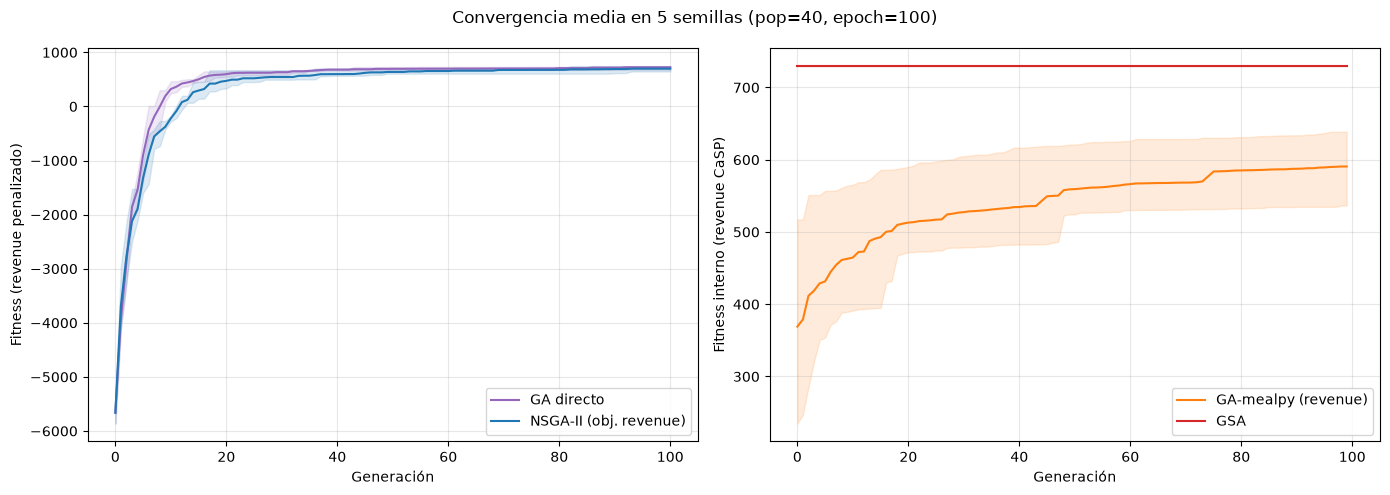

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

panel_specs = {
    0: [("ga_direct", "C4", "GA directo"), ("nsga2", "tab:blue", "NSGA-II (obj. revenue)")],
    1: [("ga_mealpy", "C1", "GA-mealpy (revenue)"), ("gsa", "C3", "GSA")],
}
for ax, specs in zip(axes, panel_specs.values()):
    for name, color, label in specs:
        stack = np.vstack([curves[(name, seed)] for seed in SEEDS])
        length = min(stack.shape[1], EPOCH + 1)
        stack = stack[:, :length]
        generations = np.arange(length)
        ax.plot(generations, stack.mean(axis=0), color=color, label=label)
        ax.fill_between(generations, stack.min(axis=0), stack.max(axis=0), color=color, alpha=0.15)
    ax.set_xlabel("Generación")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Fitness (revenue penalizado)")
axes[1].set_ylabel("Fitness interno (revenue CaSP)")
fig.suptitle(f"Convergencia media en {len(SEEDS)} semillas (pop={POP_SIZE}, epoch={EPOCH})")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "comparison_convergence.png", dpi=150, bbox_inches="tight")
plt.show()


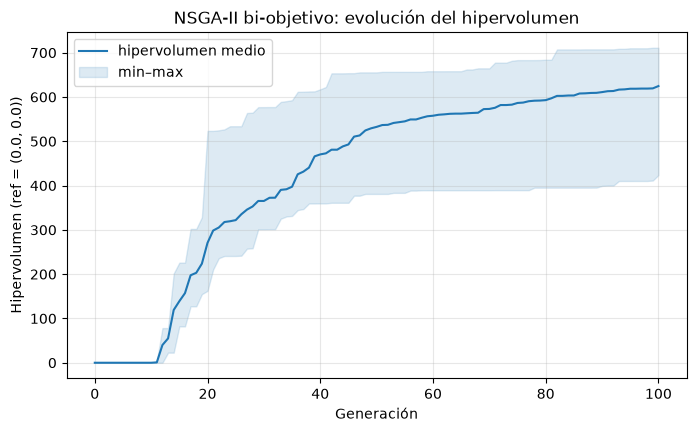

In [10]:
from craft.ga.nsga2 import hypervolume

hv_reference = (0.0, 0.0)
hv_curves = []
for seed in SEEDS:
    history = fronts[seed]["pareto_history"]
    hv_curves.append([hypervolume(front, hv_reference) for front in history])
hv_stack = np.array(
    [np.pad(curve, (0, EPOCH + 1 - len(curve)), constant_values=curve[-1]) for curve in hv_curves]
)

fig, ax = plt.subplots(figsize=(8, 4.5))
generations = np.arange(EPOCH + 1)
ax.plot(generations, hv_stack.mean(axis=0), color="tab:blue", label="hipervolumen medio")
ax.fill_between(generations, hv_stack.min(axis=0), hv_stack.max(axis=0), color="tab:blue", alpha=0.15, label="min–max")
ax.set_xlabel("Generación")
ax.set_ylabel(f"Hipervolumen (ref = {hv_reference})")
ax.set_title("NSGA-II bi-objetivo: evolución del hipervolumen")
ax.grid(alpha=0.3)
ax.legend()
fig.savefig(RESULTS_DIR / "comparison_hypervolume.png", dpi=150, bbox_inches="tight")
plt.show()


## 7. El frente de Pareto frente a los métodos mono-objetivo

La figura clave, en el plano **estricto**: revenue penalizado (métrica común
que descuenta los conflictos reales del horario decodificado, λ = 2) frente a
equidad. Cada ejecución de NSGA-II traza un fragmento de frente (puntos
azules; estrella = *knee* de la última semilla); cada método mono-objetivo
solo aporta **un punto** por semilla (círculos huecos). El greedy queda en el
interior del área dominada.


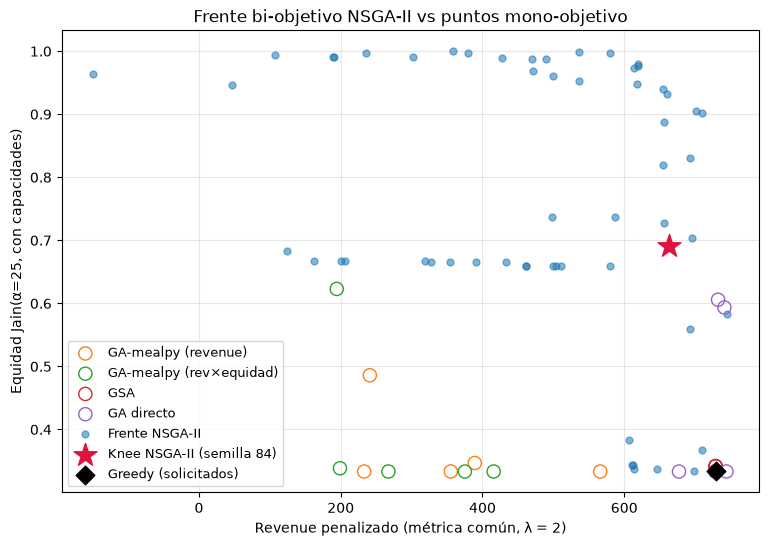

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))

point_colors = {
    "ga_mealpy": ("C1", "GA-mealpy (revenue)"),
    "ga_mealpy_fair": ("C2", "GA-mealpy (rev×equidad)"),
    "gsa": ("C3", "GSA"),
    "ga_direct": ("C4", "GA directo"),
}
for name, (color, label) in point_colors.items():
    group = results[results["method"] == name]
    ax.scatter(group["penalized"], group["fairness_jain"], facecolors="none", edgecolors=color, s=90, label=label, zorder=3)

for seed, extras in fronts.items():
    front = extras["front"]
    ax.scatter(front["penalized"], front["fairness_jain"], color="tab:blue", s=25, alpha=0.55, zorder=2,
               label="Frente NSGA-II" if seed == SEEDS[0] else None)

knee84 = fronts[SEEDS[-1]]
k = knee84["knee"]
ax.scatter([knee84["front"]["penalized"].iloc[k]], [knee84["front"]["fairness_jain"].iloc[k]],
           marker="*", s=300, color="crimson", zorder=4, label="Knee NSGA-II (semilla 84)")

ax.scatter([greedy_row["penalized"]], [greedy_row["fairness_jain"]], marker="D", s=90, color="black", zorder=4, label="Greedy (solicitados)")

ax.set_xlabel("Revenue penalizado (métrica común, λ = 2)")
ax.set_ylabel(f"Equidad Jain(α={ALPHA['jain']:g}, con capacidades)")
ax.set_title("Frente bi-objetivo NSGA-II vs puntos mono-objetivo")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
fig.savefig(RESULTS_DIR / "comparison_pareto_vs_mono.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Solución compromiso (knee) y reparto por RU

Marey de la solución *knee* de la última semilla y su reparto de capacidad
por RU frente al reparto solicitado.


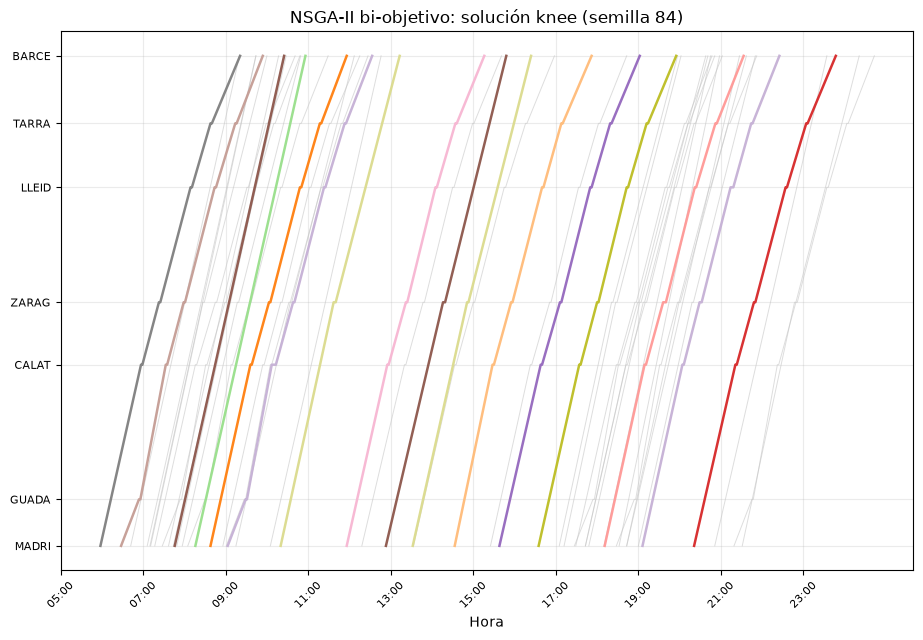

,solicitados,knee,capacidad (%),asignado (%)
3,15,4,30.0,25.00
2,11,3,22.0,18.75
1,24,9,48.0,56.25


In [12]:
from craft.ga.plotting import _marey, service_colors

knee_real, knee_mask = best_solutions["nsga2"]

fig, ax = plt.subplots(figsize=(11, 7))
checker = ga_problem.conflict_checkers[0]
ga_problem.schedule_manager.update_from_solution(knee_real)
schedules = dict(ga_problem.schedule_manager.updated_schedule)

service_rus = {sid: ga_problem.revenue_behavior[sid]["ru"] for sid in ga_problem.service_ids}
colors = service_colors(ga_problem)
stations = {sta.id: sta for svc in ga_problem.services for sta in svc.line.stations}

background = {
    sid: ga_problem.requested_schedules[sid]
    for sid, planned in zip(ga_problem.service_ids, knee_mask)
    if not planned
}
_marey(ax, background, checker.km, "0.78", "-", 0.7, 0.6)
for sid, planned in zip(ga_problem.service_ids, knee_mask):
    if planned:
        _marey(ax, {sid: schedules[sid]}, checker.km, colors[sid], "-", 1.8, 0.95)

ax.set_xticks(list(range(5 * 60, 24 * 60, 120)))
ax.set_xticklabels(
    [f"{t // 60:02d}:{t % 60:02d}" for t in ax.get_xticks()],
    rotation=45,
    fontsize=8,
)
ax.set_yticks([checker.km[s] for s in checker.corridor_ids])
ax.set_yticklabels(
    [stations[s].short_name if s in stations else s for s in checker.corridor_ids],
    fontsize=8,
)
ax.set_xlabel("Hora")
ax.grid(alpha=0.25)
ax.set_title("NSGA-II bi-objetivo: solución knee (semilla 84)")
fig.savefig(RESULTS_DIR / "comparison_knee_marey.png", dpi=150, bbox_inches="tight")
plt.show()

requested_counts = pd.Series({ru: 0 for ru in CAPACITIES}, dtype=float)
for params in ga_problem.revenue_behavior.values():
    requested_counts[params["ru"]] += 1
knee_counts = pd.Series({ru: 0 for ru in CAPACITIES}, dtype=float)
for sid, planned in zip(ga_problem.service_ids, knee_mask):
    if planned:
        knee_counts[service_rus[sid]] += 1

ru_table = pd.DataFrame(
    {
        "solicitados": requested_counts.astype(int),
        "knee": knee_counts.astype(int),
        "capacidad (%)": pd.Series(CAPACITIES).round(2),
        "asignado (%)": (100 * knee_counts / knee_counts.sum()).round(2),
    }
)
ru_table


## 9. Discusión de resultados

**1) La aproximación publicada deja conflictos reales y servicios
inoperativos cuando se mide con el verificador común.** GA-mealpy (M1)
declara 17 trenes pero solo **15,2 ± 0,8 resultan operativos** (la cota
secuencial de salidas intermedias no se impone al muestrear: si la salida
previa se retrasa, el tiempo de operación se comprime y el servicio deja de
ser viable), y su horario operativo arrastra 3,0 ± 2,1 conflictos: la matriz
de conflictos se evaluó en los horarios *solicitados* y las salidas
optimizadas dentro del margen del IM crean interferencias nuevas que su
objetivo no ve. Resultado estricto: **356,93 ± 135,59** frente a
575,05 ± 27,68 crudos.

**2) El GSA reparado alcanza el techo estructural del enfoque de dos etapas
— y ese techo es el greedy.** Con la reparación por `cumulative_shifts` y la
población sembrada con el horario solicitado (P0), el GSA pasa de colapsar
(2,0 ± 0,7 trenes operativos y 57,45 de penalizado en la primera versión de
este cuaderno) a **728,82 ± 0,01 sin conflictos y 17,0 trenes**: exactamente
el techo que impone su máscara estática — la heurística greedy sobre los
horarios solicitados (729,53) — porque las salidas optimizadas solo pueden
degradar el revenue de una máscara fija, nunca planificar más trenes. El GA
directo, sin operador de reparación externo (factibilidad por construcción),
queda estadísticamente indistinguible en revenue estricto (W = 6,
p = 0,8125) pero planifica **17,6 ± 0,9 trenes**, por encima del techo
greedy en las semillas en las que su máscara evolutiva salva servicios que
la heurística descartaba. Sin reparación, en cambio, GA directo vs GSA era
5/5 a favor del directo (p = 0,0625): la comparación solo es justa con el
backend reparado.

**3) La equidad del enfoque del paper 2 no sobrevive al filtro de
operatividad.** M2 (`revenue × Jain(25)`) persigue la equidad sobre la
máscara heurística, pero esa máscara incluye servicios que luego resultan
inoperativos: su Jain **operativo** cae a 0,39 ± 0,13 con solo 11,6 ± 2,4
trenes, y su resultado estricto es 290,30 ± 101,26. La mejor equidad del
frente de NSGA-II supera a M2 en 5/5 semillas (W = 0, p = 0,0625), y todos
los puntos de M1/M2 quedan en la región dominada del plano de la sección 7.

**4) NSGA-II convierte el trade-off revenue–equidad en un objeto medible.**
Donde cada método mono-objetivo aporta un punto por semilla, NSGA-II traza
frentes de 8–22 puntos: en el extremo de equidad alcanza Jain ≈ 0,99
(planificando más trenes de los RUs pequeños y aceptando conflictos que solo
castigan el primer objetivo); en el extremo de revenue, soluciones sin
conflictos. El *knee* de la semilla 84 es un buen compromiso: **663,82
penalizado sin conflictos, 16 trenes, Jain 0,692, inequidad 17,54 %**.
Frente al GA directo, el mejor punto estricto del frente es inferior en 5/5
semillas pero sin significancia con n = 5 (W = 4, p = 0,4375): el precio de
introducir el segundo objetivo queda **visible y cuantificado**, en lugar de
oculto en un peso α fijado a ciegas como en el enfoque mono-objetivo.

**5) La instancia es desequilibrada de facto (capacidades 48/22/30 %) y los
métodos solo-revenue concentran la capacidad en RU1.** El greedy asigna
10/4/3 trenes (59/24/18 %) con Jain 0,333 e inequidad 31,47 %; el knee
redistribuye capacidad hacia el RU3 (asignación 56/19/25 %, inequidad
17,54 %, Jain 0,692) manteniendo un revenue sin conflictos cercano al
extremo.

**6) La codificación directa es además la más barata por evaluación.** Con
el mismo presupuesto (4000 evaluaciones): GA directo 3,77 ± 0,25 s y
NSGA-II 4,87 ± 0,22 s (≈ +30 % por el orden de frentes sobre 2N individuos)
frente a 7,96–8,00 s de los GA-mealpy y 7,07 ± 0,03 s del GSA (la
reparación por movimiento añade coste al backend antiguo).

**7) Limitaciones y trabajo futuro.**
(a) Los puntos del frente en el extremo de equidad suelen arrastrar
conflictos (la equidad solo depende de la máscara): refinamiento natural =
dominación por restricciones de Deb (infactible < factible) o reparación.
(b) n = 5 semillas, un único corredor unidireccional y 3 RUs: replicar en
los escenarios balanced/semi/unbalanced de 5 RUs del paper fair-oriented
(con el runner batch `scripts/run_comparison.py`).
(c) La referencia del hipervolumen (0, 0) anula las primeras generaciones;
para las curvas del paper conviene una referencia tipo nadir.
(d) El GSA reparado confirma que la cota del esquema de dos etapas es el
greedy de los horarios solicitados; superar ese techo exige que la máscara
evolucione — es la tesis del encoding directo y se cuantifica aquí.
(e) Reproducibilidad: el desempate de la heurística CaSP es ahora
determinista (P2: revenue descendente, id ascendente), por lo que las
ejecuciones son bit-a-bit reproducibles entre procesos.


### Artefactos generados (`data/results/`)

| Fichero | Contenido |
|---|---|
| `comparison_runs.csv` | Todas las métricas de todas las ejecuciones (26 filas). |
| `comparison_summary.csv` | Tabla media ± desviación por método. |
| `comparison_pareto_seed{7,21,42,63,84}.csv` | Frentes de NSGA-II medidos con el evaluador común. |
| `comparison_convergence.png` | Curvas de convergencia (2 paneles). |
| `comparison_hypervolume.png` | Evolución del hipervolumen de NSGA-II. |
| `comparison_pareto_vs_mono.png` | Frente vs puntos mono-objetivo (figura clave). |
| `comparison_knee_marey.png` | Marey de la solución knee (semilla 84). |
| `benchmark/synthetic_timetable/` | Salida del runner batch (`scripts/run_comparison.py`). |
